In [6]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [7]:
train_df = pd.read_csv('../dados/train_processado.csv')
test_df = pd.read_csv('../dados/test_processado.csv')

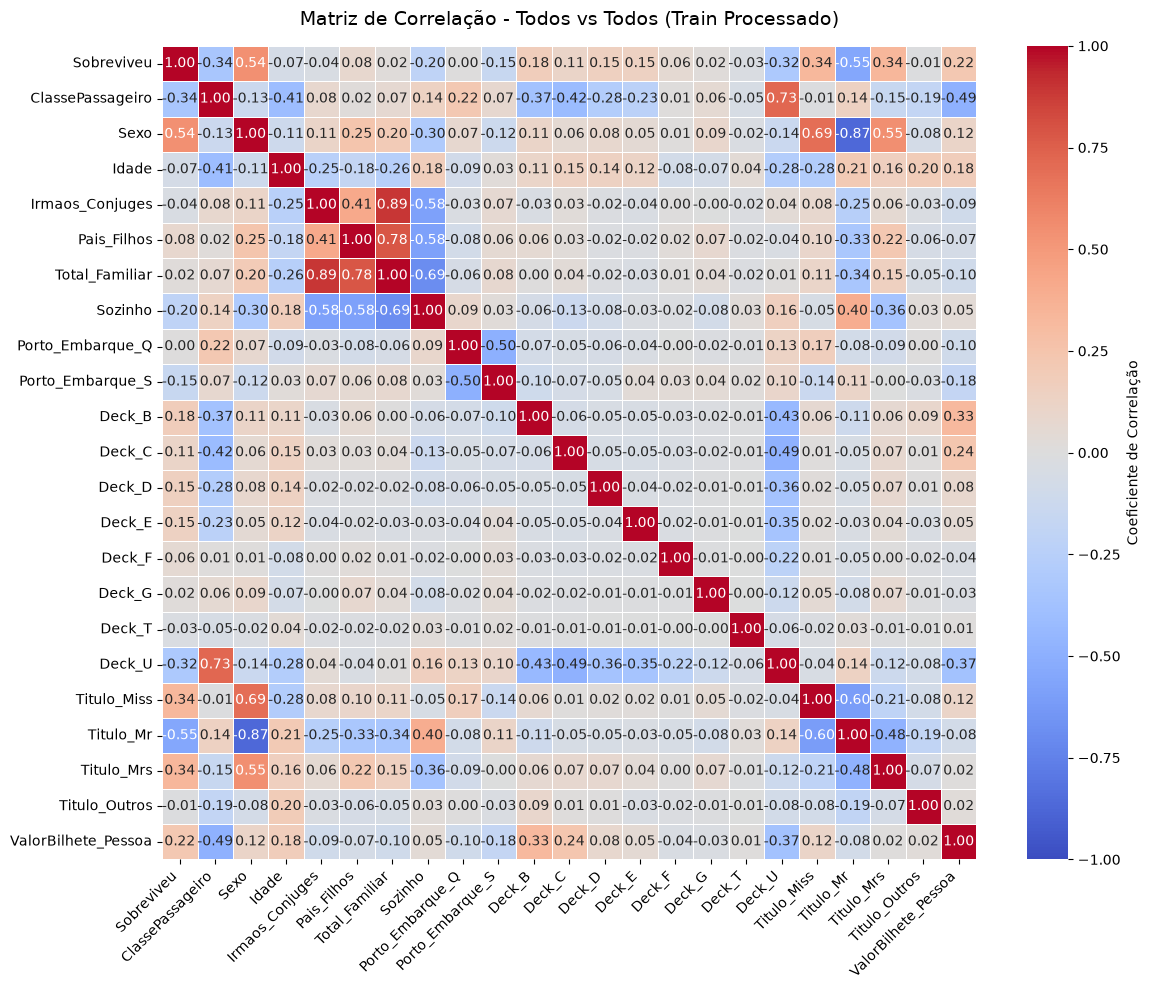

In [8]:
colunas_analise = train_df.select_dtypes(include=['number']).drop(columns=['Id_Passageiro'], errors='ignore')

# 3. Calcula a matriz de correlação "todos contra todos"
matriz_correlacao = colunas_analise.corr()

# 4. Configura o visual do gráfico colorido (Heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(
    matriz_correlacao, 
    annot=True,              # Mostra os valores numéricos dentro de cada célula
    fmt=".2f",               # Formata os números com 2 casas decimais
    cmap='coolwarm',         # Esquema de cores (azul para negativo, vermelho para positivo)
    vmin=-1, vmax=1,         # Limites da escala de correlação
    linewidths=0.5,          # Linhas divisorias entre as células
    cbar_kws={'label': 'Coeficiente de Correlação'}
)

plt.title('Matriz de Correlação - Todos vs Todos (Train Processado)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
//manter apenas ValorBilhete_Pessoa, titulo_mrs, titulo_mr, titulo_miss, sozinho, sexo, classepassageiro

In [16]:
print("--- 2. PORCENTAGEM DE MORTE E SOBREVIVÊNCIA POR SEXO ---")
sexo_analise = train_df.groupby('Sexo')['Sobreviveu'].agg(
    Total='count',
    Sobreviventes='sum'
)
sexo_analise['Mortos'] = sexo_analise['Total'] - sexo_analise['Sobreviventes']
sexo_analise['% Sobrevivência'] = (sexo_analise['Sobreviventes'] / sexo_analise['Total']) * 100
sexo_analise['% Mortalidade'] = (sexo_analise['Mortos'] / sexo_analise['Total']) * 100

# Renomeando o índice para facilitar a leitura (0 = Masculino, 1 = Feminino com base no seu map anterior)
sexo_analise.index = ['Masculino (0)', 'Feminino (1)']
display(sexo_analise[['Total', '% Sobrevivência', '% Mortalidade']])

--- 2. PORCENTAGEM DE MORTE E SOBREVIVÊNCIA POR SEXO ---


,Total,% Sobrevivência,% Mortalidade
Masculino (0),577,18.890815,81.109185
Feminino (1),314,74.203822,25.796178


(0.0, 100.0)

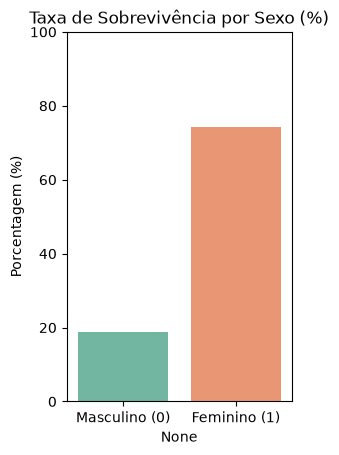

In [20]:
plt.subplot(1, 2, 1)
sns.barplot(
    x=sexo_analise.index, 
    y=sexo_analise['% Sobrevivência'], 
    hue=sexo_analise.index, 
    palette='Set2',
    legend=False
)
plt.title('Taxa de Sobrevivência por Sexo (%)')
plt.ylabel('Porcentagem (%)')
plt.ylim(0, 100)

In [18]:
print("--- 3. PORCENTAGEM DE MORTE E SOBREVIVÊNCIA POR CLASSE DE PASSAGEIRO ---")
classe_analise = train_df.groupby('ClassePassageiro')['Sobreviveu'].agg(
    Total='count',
    Sobreviventes='sum'
)
classe_analise['Mortos'] = classe_analise['Total'] - classe_analise['Sobreviventes']
classe_analise['% Sobrevivência'] = (classe_analise['Sobreviventes'] / classe_analise['Total']) * 100
classe_analise['% Mortalidade'] = (classe_analise['Mortos'] / classe_analise['Total']) * 100

display(classe_analise[['Total', '% Sobrevivência', '% Mortalidade']])

--- 3. PORCENTAGEM DE MORTE E SOBREVIVÊNCIA POR CLASSE DE PASSAGEIRO ---


,Total,% Sobrevivência,% Mortalidade
ClassePassageiro,,,
1,216,62.962963,37.037037
2,184,47.282609,52.717391
3,491,24.236253,75.763747


(0.0, 100.0)

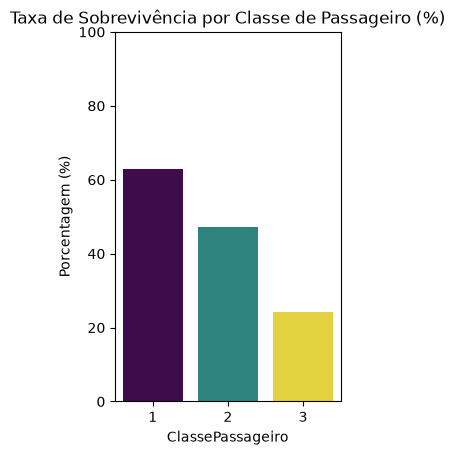

In [19]:
plt.subplot(1, 2, 2)
sns.barplot(
    x=classe_analise.index, 
    y=classe_analise['% Sobrevivência'], 
    hue=classe_analise.index, 
    palette='viridis',
    legend=False
)
plt.title('Taxa de Sobrevivência por Classe de Passageiro (%)')
plt.ylabel('Porcentagem (%)')
plt.ylim(0, 100)